# Regresja wielomianowa

Czasem dane układają się w krzywą, a nie w prostą — np. **wysokość piłki w czasie lotu**
(rzut pionowy: piłka wznosi się i opada).

Plan:
1. generujemy dane w kształcie paraboli,
2. próbujemy dopasować prostą (za mało elastyczną),
3. używamy sztuczki z nową cechą x²,
4. sprawdzamy, co się dzieje przy większych stopniach (przeuczenie),
5. wybieramy stopień na danych testowych.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

## Krok 1 — dane: lot piłki

In [ ]:
rng = np.random.default_rng(seed=42)

# czas lotu piłki: 40 pomiarów od 0 do 4 sekund
czas = rng.uniform(0, 4, size=40)

# wysokość = parabola + szum (rzut pionowy w polu grawitacyjnym)
wysokosc = 20 * czas - 5 * czas**2 + rng.normal(0, 1.5, size=40)

X = czas.reshape(-1, 1)
y = wysokosc

plt.figure(figsize=(8, 5))
plt.scatter(czas, wysokosc, color="steelblue", alpha=0.8)
plt.xlabel("Czas [s]")
plt.ylabel("Wysokość [m]")
plt.title("Wysokość piłki w czasie — dane w kształcie paraboli")
plt.grid(alpha=0.3)
plt.show()

: 

## Krok 2 — prosta nie wystarcza

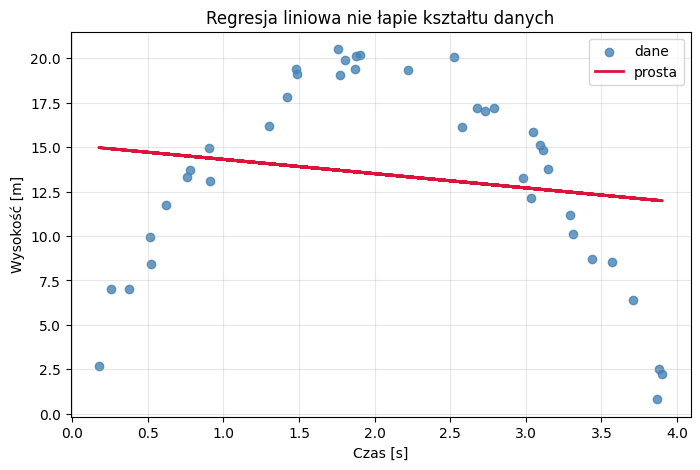

In [3]:
model_prosta = LinearRegression()
model_prosta.fit(X, y)

plt.figure(figsize=(8, 5))
plt.scatter(czas, wysokosc, color="steelblue", alpha=0.8, label="dane")
plt.plot(czas, model_prosta.predict(X), color="crimson", linewidth=2, label="prosta")
plt.xlabel("Czas [s]")
plt.ylabel("Wysokość [m]")
plt.title("Regresja liniowa nie łapie kształtu danych")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Krok 3 — sztuczka: nowa cecha x²

Tworzymy **drugą kolumnę** zawierającą x². Potem robimy **zwykłą regresję liniową
na dwóch kolumnach** — dokładnie ta sama idea co na wykładzie ("wielomian to
przebrana regresja liniowa").

In [4]:
# PolynomialFeatures tworzy nowe kolumny: [x, x^2]
poly = PolynomialFeatures(degree=2, include_bias=False)
X_wielomian = poly.fit_transform(X)

print("Pierwsze 3 wiersze — kolumny [x, x^2]:")
print(X_wielomian[:3])

Pierwsze 3 wiersze — kolumny [x, x^2]:
[[ 3.09582419  9.58412744]
 [ 1.75551376  3.08182856]
 [ 3.43439168 11.79504621]]


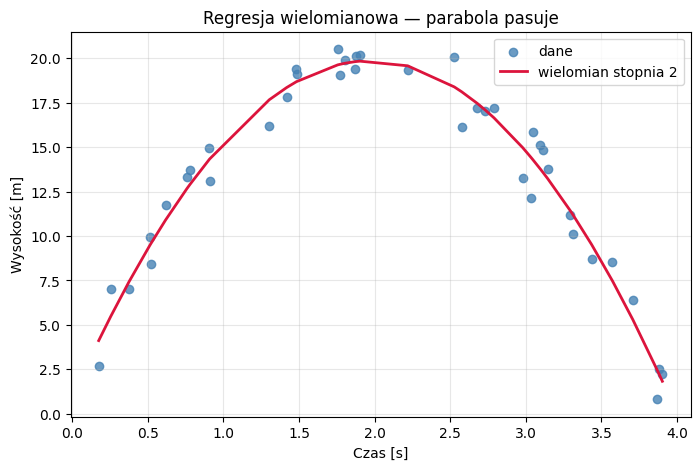

In [5]:
model_wielomian = LinearRegression()
model_wielomian.fit(X_wielomian, y)

# do rysowania krzywej sortujemy punkty po czasie
kolejnosc = np.argsort(czas)

plt.figure(figsize=(8, 5))
plt.scatter(czas, wysokosc, color="steelblue", alpha=0.8, label="dane")
plt.plot(czas[kolejnosc], model_wielomian.predict(X_wielomian[kolejnosc]),
         color="crimson", linewidth=2, label="wielomian stopnia 2")
plt.xlabel("Czas [s]")
plt.ylabel("Wysokość [m]")
plt.title("Regresja wielomianowa — parabola pasuje")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Krok 4 — większy stopień = ryzyko przeuczenia

Stopień 9 "prześlizguje się" przez punkty — zamiast trendu łapie **szum**.

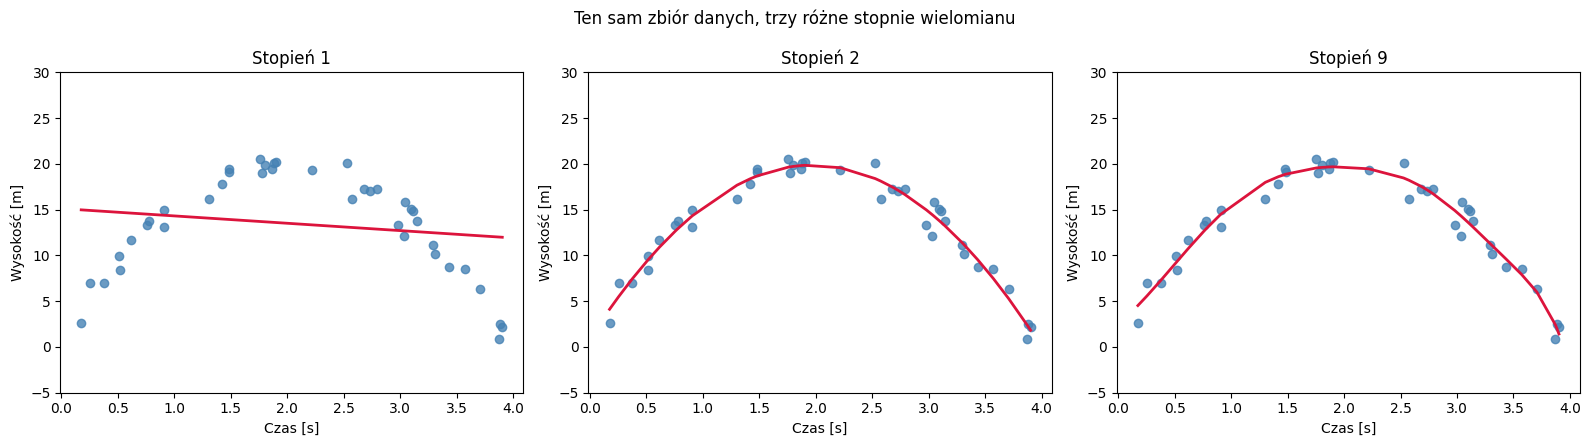

In [6]:
stopnie = [1, 2, 9]

fig, osie = plt.subplots(1, 3, figsize=(16, 4.5))

for os, stopien in zip(osie, stopnie):
    # nowe cechy: x, x^2, ..., x^stopien
    poly = PolynomialFeatures(degree=stopien, include_bias=False)
    X_p = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_p, y)

    os.scatter(czas, wysokosc, color="steelblue", alpha=0.8)
    os.plot(czas[kolejnosc], model.predict(X_p[kolejnosc]), color="crimson", linewidth=2)
    os.set_title(f"Stopień {stopien}")
    os.set_xlabel("Czas [s]")
    os.set_ylabel("Wysokość [m]")
    os.set_ylim(-5, 30)

plt.suptitle("Ten sam zbiór danych, trzy różne stopnie wielomianu")
plt.tight_layout()
plt.show()

## Krok 5 — jak wybrać stopień? Dane treningowe vs testowe

1. dzielimy dane na **treningowe** (do nauki modelu) i **testowe** (odłożone "pod szkło"),
2. uczymy model **tylko** na danych treningowych,
3. mierzymy błąd osobno na obu zbiorach,
4. wybieramy stopień na dnie "doliny" błędu testowego.

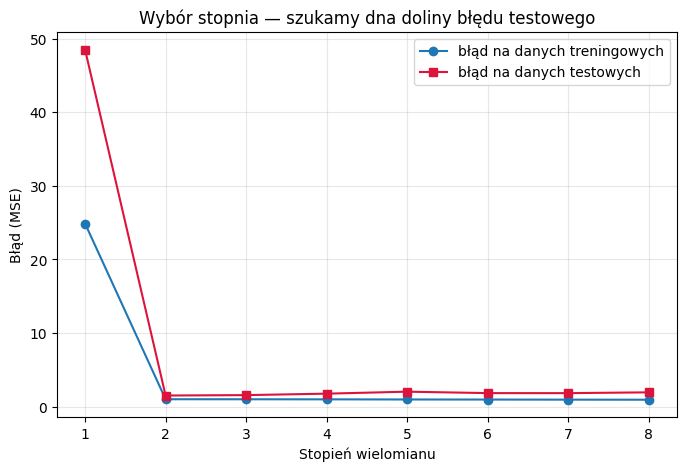

Najlepszy stopień według danych testowych: 2


In [7]:
# 70% danych do nauki, 30% do sprawdzenia
X_tren, X_test, y_tren, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

stopnie = range(1, 9)
blad_trening = []
blad_test = []

for stopien in stopnie:
    # nowe cechy: x, x^2, ..., x^stopien
    poly = PolynomialFeatures(degree=stopien, include_bias=False)
    X_tren_p = poly.fit_transform(X_tren)
    X_test_p = poly.transform(X_test)

    # model uczymy TYLKO na danych treningowych
    model = LinearRegression()
    model.fit(X_tren_p, y_tren)

    # błąd mierzymy osobno na obu zbiorach
    blad_trening.append(mean_squared_error(y_tren, model.predict(X_tren_p)))
    blad_test.append(mean_squared_error(y_test, model.predict(X_test_p)))

plt.figure(figsize=(8, 5))
plt.plot(stopnie, blad_trening, "o-", label="błąd na danych treningowych")
plt.plot(stopnie, blad_test, "s-", color="crimson", label="błąd na danych testowych")
plt.xlabel("Stopień wielomianu")
plt.ylabel("Błąd (MSE)")
plt.title("Wybór stopnia — szukamy dna doliny błędu testowego")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

najlepszy_stopien = list(stopnie)[int(np.argmin(blad_test))]
print(f"Najlepszy stopień według danych testowych: {najlepszy_stopien}")

## Wnioski

- regresja wielomianowa = regresja liniowa na "przebranych" cechach (x, x², x³, ...),
- za niski stopień → **niedouczenie**, za wysoki → **przeuczenie**,
- o stopniu decydujemy na danych **testowych**, których model nie widział,
- współczynniki znajduje komputer — my wybieramy tylko stopień.